In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split

train_df = pd.read_csv("../train_data.csv")
test_df = pd.read_csv("../test_data.csv")

print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

train_df.head()

Training shape: (9864, 18)
Testing shape: (2466, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,8,732.25,0,0.0,34,1345.755952,0.005128,0.013342,12.274195,0.8,May,3,3,3,2,Returning_Visitor,False,False
1,0,0.00,0,0.0,4,157.200000,0.040000,0.100000,0.000000,0.0,Oct,1,8,3,1,Returning_Visitor,True,False
2,0,0.00,0,0.0,4,42.000000,0.000000,0.050000,0.000000,0.0,Dec,2,10,1,2,Returning_Visitor,False,False
3,2,338.00,0,0.0,17,1205.566667,0.012500,0.037500,19.236250,0.8,May,3,2,2,2,Returning_Visitor,False,True
4,0,0.00,0,0.0,32,827.646212,0.000000,0.000587,54.676348,0.0,Mar,2,2,7,2,Returning_Visitor,False,True


In [2]:
print(train_df.info())

<class 'pandas.DataFrame'>
RangeIndex: 9864 entries, 0 to 9863
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           9864 non-null   int64  
 1   Administrative_Duration  9864 non-null   float64
 2   Informational            9864 non-null   int64  
 3   Informational_Duration   9864 non-null   float64
 4   ProductRelated           9864 non-null   int64  
 5   ProductRelated_Duration  9864 non-null   float64
 6   BounceRates              9864 non-null   float64
 7   ExitRates                9864 non-null   float64
 8   PageValues               9864 non-null   float64
 9   SpecialDay               9864 non-null   float64
 10  Month                    9864 non-null   str    
 11  OperatingSystems         9864 non-null   int64  
 12  Browser                  9864 non-null   int64  
 13  Region                   9864 non-null   int64  
 14  TrafficType              9864 non-n

In [3]:
print(test_df.info())

<class 'pandas.DataFrame'>
RangeIndex: 2466 entries, 0 to 2465
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           2466 non-null   int64  
 1   Administrative_Duration  2466 non-null   float64
 2   Informational            2466 non-null   int64  
 3   Informational_Duration   2466 non-null   float64
 4   ProductRelated           2466 non-null   int64  
 5   ProductRelated_Duration  2466 non-null   float64
 6   BounceRates              2466 non-null   float64
 7   ExitRates                2466 non-null   float64
 8   PageValues               2466 non-null   float64
 9   SpecialDay               2466 non-null   float64
 10  Month                    2466 non-null   str    
 11  OperatingSystems         2466 non-null   int64  
 12  Browser                  2466 non-null   int64  
 13  Region                   2466 non-null   int64  
 14  TrafficType              2466 non-n

In [4]:
X = train_df.drop(columns=["Revenue"])
y = train_df["Revenue"]

X_test = test_df.drop(columns=["Revenue"])
y_test = test_df["Revenue"]

print("X shape:", X.shape)
print("y shape:", y.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X shape: (9864, 17)
y shape: (9864,)
X_test shape: (2466, 17)
y_test shape: (2466,)


In [5]:
categorical_cols = [
    "Month",
    "VisitorType",
    "Weekend",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType"
]

numerical_cols = [
    "Administrative",
    "Administrative_Duration",
    "Informational",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration",
    "BounceRates",
    "ExitRates",
    "PageValues",
    "SpecialDay"
]

print("Categorical columns:")
print(categorical_cols)

print("\nNumerical columns:")
print(numerical_cols)

print("\nNumber of categorical features:", len(categorical_cols))
print("Number of numerical features:", len(numerical_cols))

Categorical columns:
['Month', 'VisitorType', 'Weekend', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']

Numerical columns:
['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']

Number of categorical features: 7
Number of numerical features: 10


In [6]:
print(X[categorical_cols].dtypes)
print()
print(X[numerical_cols].dtypes)

Month                 str
VisitorType           str
Weekend              bool
OperatingSystems    int64
Browser             int64
Region              int64
TrafficType         int64
dtype: object

Administrative               int64
Administrative_Duration    float64
Informational                int64
Informational_Duration     float64
ProductRelated               int64
ProductRelated_Duration    float64
BounceRates                float64
ExitRates                  float64
PageValues                 float64
SpecialDay                 float64
dtype: object


In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_cols
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_cols
        )
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [8]:
print("Target values:")
print(y.unique())

print("\nTarget data types:")
print(y.dtype)

print("\nTarget distribution:")
print(y.value_counts())

Target values:
[False  True]

Target data types:
bool

Target distribution:
Revenue
False    8338
True     1526
Name: count, dtype: int64


In [9]:
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nValidation target distribution:")
print(y_val.value_counts(normalize=True) * 100)

Training features: (7891, 17)
Validation features: (1973, 17)

Training target distribution:
Revenue
False    84.526676
True     15.473324
Name: proportion, dtype: float64

Validation target distribution:
Revenue
False    84.541308
True     15.458692
Name: proportion, dtype: float64


In [10]:
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

print("Evaluation metrics imported successfully.")

Evaluation metrics imported successfully.


#### Logistic Regression

In [11]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        ))
    ]
)

logistic_model.fit(X_train, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [12]:
y_val_pred = logistic_model.predict(X_val)

y_val_prob = logistic_model.predict_proba(X_val)[:, 1]

print("Predictions generated successfully!")

Predictions generated successfully!


In [14]:
logistic_results = {
    "Model": "Logistic Regression",
    "Accuracy": accuracy_score(y_val, y_val_pred),
    "AUC": roc_auc_score(y_val, y_val_prob),
    "Precision": precision_score(y_val, y_val_pred, zero_division=0),
    "Recall": recall_score(y_val, y_val_pred, zero_division=0),
    "F1": f1_score(y_val, y_val_pred, zero_division=0),
    "MCC": matthews_corrcoef(y_val, y_val_pred)
}

print(logistic_results)

{'Model': 'Logistic Regression', 'Accuracy': 0.8352762290927521, 'AUC': 0.8970810237056258, 'Precision': 0.47959183673469385, 'Recall': 0.7704918032786885, 'F1': 0.5911949685534591, 'MCC': 0.5167690953731561}


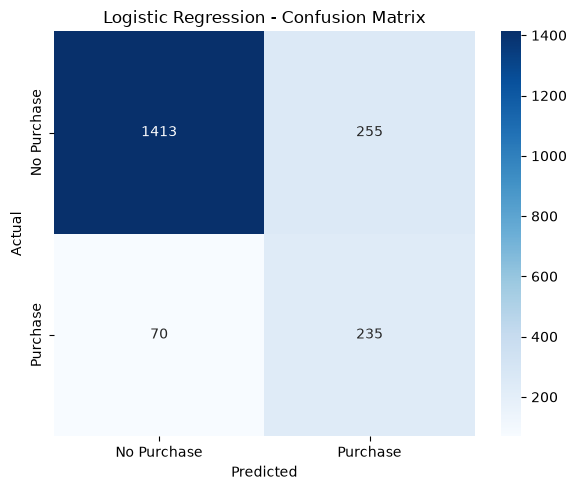

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_val, y_val_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Purchase", "Purchase"],
    yticklabels=["No Purchase", "Purchase"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()

In [16]:
results = []
results.append(logistic_results)

results_df = pd.DataFrame(results)
results_df

,Model,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.835276,0.897081,0.479592,0.770492,0.591195,0.516769


#### Decision Tree

In [17]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline

decision_tree_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(
            max_depth=10,
            min_samples_split=20,
            min_samples_leaf=10,
            class_weight="balanced",
            random_state=42
        ))
    ]
)

decision_tree_model.fit(X_train, y_train)

print("Decision Tree training completed!")

Decision Tree training completed!


In [18]:
y_val_pred_dt = decision_tree_model.predict(X_val)

y_val_prob_dt = decision_tree_model.predict_proba(X_val)[:, 1]

print("Decision Tree predictions generated!")

Decision Tree predictions generated!


In [19]:
decision_tree_results = {
    "Model": "Decision Tree",
    "Accuracy": accuracy_score(y_val, y_val_pred_dt),
    "AUC": roc_auc_score(y_val, y_val_prob_dt),
    "Precision": precision_score(y_val, y_val_pred_dt, zero_division=0),
    "Recall": recall_score(y_val, y_val_pred_dt, zero_division=0),
    "F1": f1_score(y_val, y_val_pred_dt, zero_division=0),
    "MCC": matthews_corrcoef(y_val, y_val_pred_dt)
}

print(decision_tree_results)

{'Model': 'Decision Tree', 'Accuracy': 0.8231120121642169, 'AUC': 0.8856596689861225, 'Precision': 0.4601449275362319, 'Recall': 0.8327868852459016, 'F1': 0.5927654609101517, 'MCC': 0.5267994426937602}


In [20]:
results.append(decision_tree_results)

results_df = pd.DataFrame(results)

results_df

,Model,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.835276,0.897081,0.479592,0.770492,0.591195,0.516769
1,Decision Tree,0.823112,0.885660,0.460145,0.832787,0.592765,0.526799


#### K-Nearest Neighbors (KNN)

In [21]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline

knn_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", KNeighborsClassifier(
            n_neighbors=5,
            weights="distance",
            metric="minkowski",
            p=2
        ))
    ]
)

knn_model.fit(X_train, y_train)

print("KNN training completed!")

KNN training completed!


In [22]:
y_val_pred_knn = knn_model.predict(X_val)

y_val_prob_knn = knn_model.predict_proba(X_val)[:, 1]

print("KNN predictions generated!")

KNN predictions generated!


In [23]:
knn_results = {
    "Model": "KNN",
    "Accuracy": accuracy_score(y_val, y_val_pred_knn),
    "AUC": roc_auc_score(y_val, y_val_prob_knn),
    "Precision": precision_score(y_val, y_val_pred_knn, zero_division=0),
    "Recall": recall_score(y_val, y_val_pred_knn, zero_division=0),
    "F1": f1_score(y_val, y_val_pred_knn, zero_division=0),
    "MCC": matthews_corrcoef(y_val, y_val_pred_knn)
}

print(knn_results)

{'Model': 'KNN', 'Accuracy': 0.8651799290420679, 'AUC': 0.8009267995439715, 'Precision': 0.6020942408376964, 'Recall': 0.3770491803278688, 'F1': 0.4637096774193548, 'MCC': 0.4052678171672826}


In [24]:
results.append(knn_results)

results_df = pd.DataFrame(results)

results_df

,Model,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.835276,0.897081,0.479592,0.770492,0.591195,0.516769
1,Decision Tree,0.823112,0.885660,0.460145,0.832787,0.592765,0.526799
2,KNN,0.865180,0.800927,0.602094,0.377049,0.463710,0.405268


### Naive Bayes

In [27]:
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer

nb_preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numerical_cols),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_cols
        )
    ]
)

naive_bayes_model = Pipeline(
    steps=[
        ("preprocessor", nb_preprocessor),
        ("classifier", GaussianNB())
    ]
)

naive_bayes_model.fit(X_train, y_train)

print("Naive Bayes training completed!")

Naive Bayes training completed!


In [28]:
y_val_pred_nb = naive_bayes_model.predict(X_val)

y_val_prob_nb = naive_bayes_model.predict_proba(X_val)[:, 1]

print("Naive Bayes predictions generated!")

Naive Bayes predictions generated!


In [29]:
naive_bayes_results = {
    "Model": "Naive Bayes",
    "Accuracy": accuracy_score(y_val, y_val_pred_nb),
    "AUC": roc_auc_score(y_val, y_val_prob_nb),
    "Precision": precision_score(y_val, y_val_pred_nb, zero_division=0),
    "Recall": recall_score(y_val, y_val_pred_nb, zero_division=0),
    "F1": f1_score(y_val, y_val_pred_nb, zero_division=0),
    "MCC": matthews_corrcoef(y_val, y_val_pred_nb)
}

print(naive_bayes_results)

{'Model': 'Naive Bayes', 'Accuracy': 0.7156614292954891, 'AUC': 0.7804448244682941, 'Precision': 0.3078078078078078, 'Recall': 0.6721311475409836, 'F1': 0.42224510813594235, 'MCC': 0.30254949184613694}


In [33]:
results.append(naive_bayes_results)

results_df = pd.DataFrame(results)

results_df

,Model,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.835276,0.897081,0.479592,0.770492,0.591195,0.516769
1,Decision Tree,0.823112,0.885660,0.460145,0.832787,0.592765,0.526799
2,KNN,0.865180,0.800927,0.602094,0.377049,0.463710,0.405268
3,Naive Bayes,0.715661,0.780445,0.307808,0.672131,0.422245,0.302549


### Support Vector Machine (SVM)

In [30]:
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.pipeline import Pipeline

svm_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", CalibratedClassifierCV(
            estimator=SVC(
                kernel="rbf",
                C=1.0,
                gamma="scale",
                class_weight="balanced",
                random_state=42
            ),
            method="sigmoid",
            cv=3,
            ensemble=False
        ))
    ]
)

svm_model.fit(X_train, y_train)

print("SVM training completed!")

e:\Git_pracitce\Projects\ML-Classification-Project\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM training completed!


In [31]:
y_val_pred_svm = svm_model.predict(X_val)

y_val_prob_svm = svm_model.predict_proba(X_val)[:, 1]

print("SVM predictions generated!")

SVM predictions generated!


In [32]:
svm_results = {
    "Model": "SVM",
    "Accuracy": accuracy_score(y_val, y_val_pred_svm),
    "AUC": roc_auc_score(y_val, y_val_prob_svm),
    "Precision": precision_score(y_val, y_val_pred_svm, zero_division=0),
    "Recall": recall_score(y_val, y_val_pred_svm, zero_division=0),
    "F1": f1_score(y_val, y_val_pred_svm, zero_division=0),
    "MCC": matthews_corrcoef(y_val, y_val_pred_svm)
}

print(svm_results)

{'Model': 'SVM', 'Accuracy': 0.8631525595539787, 'AUC': 0.8997818138931477, 'Precision': 0.5398633257403189, 'Recall': 0.7770491803278688, 'F1': 0.6370967741935484, 'MCC': 0.570126374849893}


In [34]:
results.append(svm_results)

results_df = pd.DataFrame(results)

results_df

,Model,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.835276,0.897081,0.479592,0.770492,0.591195,0.516769
1,Decision Tree,0.823112,0.885660,0.460145,0.832787,0.592765,0.526799
2,KNN,0.865180,0.800927,0.602094,0.377049,0.463710,0.405268
3,Naive Bayes,0.715661,0.780445,0.307808,0.672131,0.422245,0.302549
4,SVM,0.863153,0.899782,0.539863,0.777049,0.637097,0.570126


#### Create the final validation results table

In [35]:
all_results = [
    logistic_results,
    decision_tree_results,
    knn_results,
    naive_bayes_results,
    svm_results
]

results_df = pd.DataFrame(all_results)

results_df = results_df.round(4)

results_df

,Model,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.8353,0.8971,0.4796,0.7705,0.5912,0.5168
1,Decision Tree,0.8231,0.8857,0.4601,0.8328,0.5928,0.5268
2,KNN,0.8652,0.8009,0.6021,0.3770,0.4637,0.4053
3,Naive Bayes,0.7157,0.7804,0.3078,0.6721,0.4222,0.3025
4,SVM,0.8632,0.8998,0.5399,0.7770,0.6371,0.5701


In [36]:
metric_cols = [
    "Accuracy", "AUC", "Precision",
    "Recall", "F1", "MCC"
]

for col in metric_cols:
    best_idx = results_df[col].idxmax()
    print(
        f"Best {col}: "
        f"{results_df.loc[best_idx, 'Model']} "
        f"({results_df.loc[best_idx, col]:.4f})"
    )

Best Accuracy: KNN (0.8652)
Best AUC: SVM (0.8998)
Best Precision: KNN (0.6021)
Best Recall: Decision Tree (0.8328)
Best F1: SVM (0.6371)
Best MCC: SVM (0.5701)


In [37]:
models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model,
    "KNN": knn_model,
    "Naive Bayes": naive_bayes_model,
    "SVM": svm_model
}

test_results = []

for name, model in models.items():

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    test_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "AUC": roc_auc_score(y_test, y_prob),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "MCC": matthews_corrcoef(y_test, y_pred)
    })

test_results_df = pd.DataFrame(test_results)

test_results_df.round(4)

,Model,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.8333,0.8914,0.4758,0.7461,0.5810,0.5023
1,Decision Tree,0.8337,0.8750,0.4786,0.8194,0.6042,0.5375
2,KNN,0.8686,0.7750,0.6283,0.3717,0.4671,0.4156
3,Naive Bayes,0.7421,0.7776,0.3342,0.6702,0.4460,0.3326
4,SVM,0.8621,0.9007,0.5396,0.7487,0.6272,0.5563


#### 1. Test Dataset Performance Comparison

| Model | Accuracy | AUC | Precision | Recall | F1 | MCC |
|---|---:|---:|---:|---:|---:|---:|
| Logistic Regression | 83.33% | 89.14% | 47.58% | 74.61% | 58.10% | 0.5023 |
| Decision Tree | 83.37% | 87.50% | 47.86% | **81.94%** | 60.42% | 0.5375 |
| KNN | **86.86%** | 77.50% | **62.83%** | 37.17% | 46.71% | 0.4156 |
| Naive Bayes | 74.21% | 77.76% | 33.42% | 67.02% | 44.60% | 0.3326 |
| SVM | 86.21% | **90.07%** | 53.96% | 74.87% | **62.72%** | **0.5563** |

#### 2. Model Observations

1. **Logistic Regression:** Provides a reasonable baseline, with an AUC of 89.14% and recall of 74.61%.
2. **Decision Tree:** Has the highest recall (81.94%), identifying the largest proportion of actual purchasing customers.
3. **KNN:** Achieves the highest accuracy (86.86%) and precision (62.83%), but has relatively low recall (37.17%).
4. **Naive Bayes:** Has the lowest accuracy (74.21%) and MCC (0.3326) among the models.
5. **SVM:** Achieves the best AUC (90.07%), F1 score (62.72%), and MCC (0.5563), offering the strongest overall balance.

**Overall:** SVM is the best-balanced model based on AUC, F1, and MCC. The Decision Tree may be preferable when identifying as many purchasing customers as possible is the priority.

### Save all five trained models

In [39]:
import os
import joblib

# Create model folder if it does not exist
os.makedirs("../model", exist_ok=True)

# Save all five trained pipelines
joblib.dump(logistic_model, "../model/logistic_regression.joblib")
joblib.dump(decision_tree_model, "../model/decision_tree.joblib")
joblib.dump(knn_model, "../model/knn.joblib")
joblib.dump(naive_bayes_model, "../model/naive_bayes.joblib")
joblib.dump(svm_model, "../model/svm.joblib")

print("All five models saved successfully!")

All five models saved successfully!


In [40]:
os.listdir("../model")

['decision_tree.joblib',
 'knn.joblib',
 'logistic_regression.joblib',
 'naive_bayes.joblib',
 'svm.joblib']

In [41]:
import joblib
import os

model_files = [
    "logistic_regression.joblib",
    "decision_tree.joblib",
    "knn.joblib",
    "naive_bayes.joblib",
    "svm.joblib"
]

for file in model_files:
    model_path = f"../model/{file}"
    loaded_model = joblib.load(model_path)
    print(f"{file} - Loaded successfully")

logistic_regression.joblib - Loaded successfully
decision_tree.joblib - Loaded successfully
knn.joblib - Loaded successfully
naive_bayes.joblib - Loaded successfully
svm.joblib - Loaded successfully


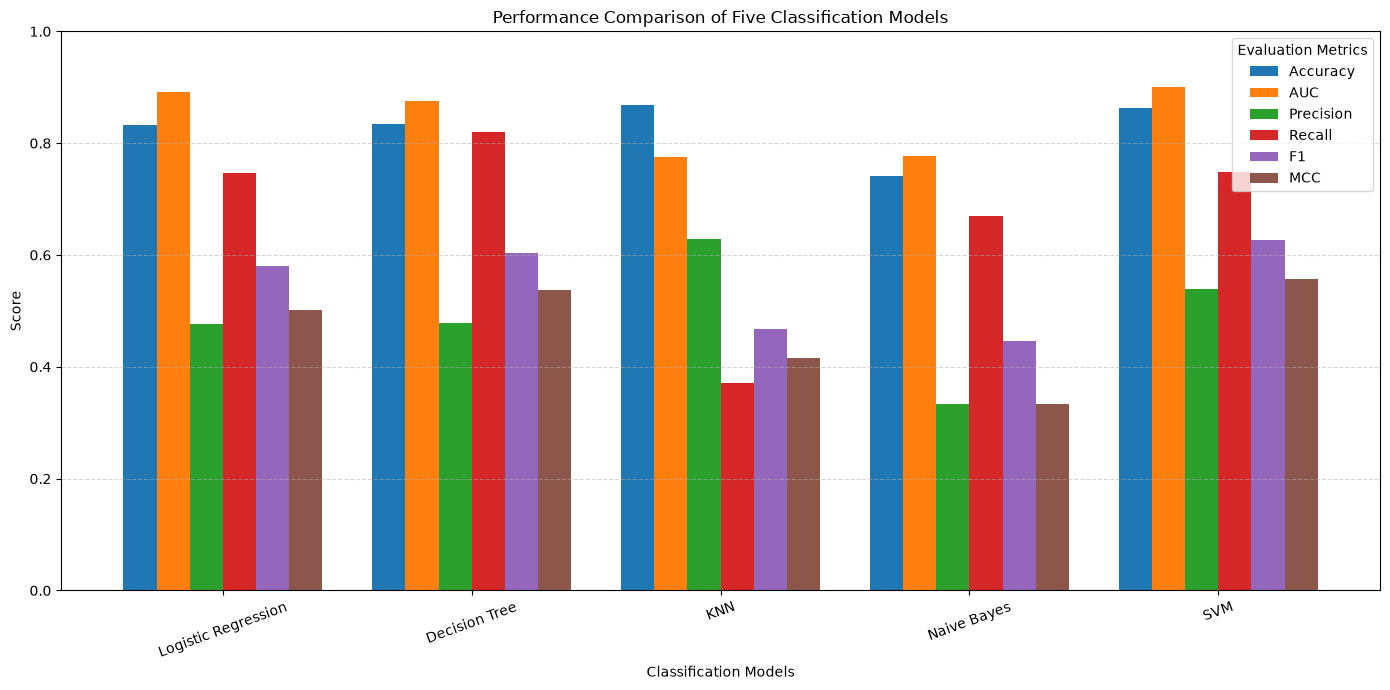

In [42]:
import matplotlib.pyplot as plt
import seaborn as sns

metrics = ["Accuracy", "AUC", "Precision", "Recall", "F1", "MCC"]

plot_df = test_results_df.set_index("Model")[metrics]

plot_df.plot(
    kind="bar",
    figsize=(14, 7),
    width=0.8
)

plt.title("Performance Comparison of Five Classification Models")
plt.xlabel("Classification Models")
plt.ylabel("Score")
plt.xticks(rotation=20)
plt.ylim(0, 1)
plt.legend(title="Evaluation Metrics")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

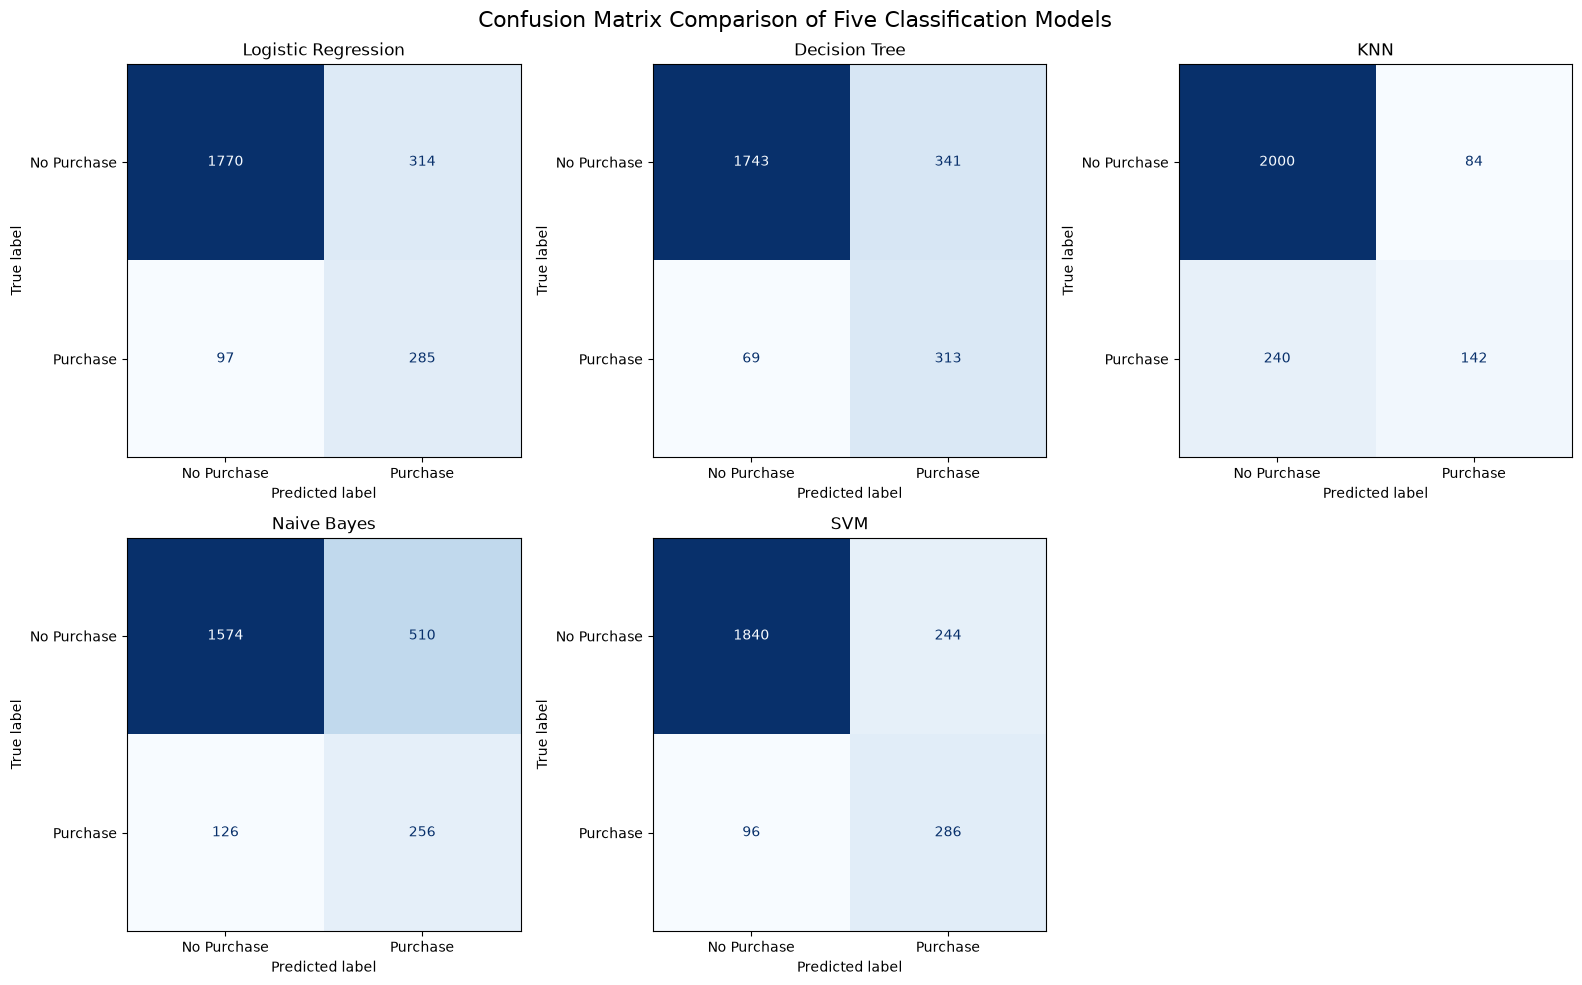

In [43]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 3, figsize=(16, 10))

for ax, (name, model) in zip(axes.flat, models.items()):

    y_pred = model.predict(X_test)

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        display_labels=["No Purchase", "Purchase"],
        cmap="Blues",
        ax=ax,
        colorbar=False
    )

    ax.set_title(name)

# Remove the unused sixth subplot
fig.delaxes(axes.flat[5])

plt.suptitle("Confusion Matrix Comparison of Five Classification Models",
             fontsize=16)

plt.tight_layout()
plt.show()

In [44]:
from sklearn.metrics import classification_report

for name, model in models.items():

    print("=" * 60)
    print(name)
    print("=" * 60)

    y_pred = model.predict(X_test)

    print(classification_report(
        y_test,
        y_pred,
        target_names=["No Purchase", "Purchase"],
        zero_division=0
    ))

Logistic Regression
              precision    recall  f1-score   support

 No Purchase       0.95      0.85      0.90      2084
    Purchase       0.48      0.75      0.58       382

    accuracy                           0.83      2466
   macro avg       0.71      0.80      0.74      2466
weighted avg       0.87      0.83      0.85      2466

Decision Tree
              precision    recall  f1-score   support

 No Purchase       0.96      0.84      0.89      2084
    Purchase       0.48      0.82      0.60       382

    accuracy                           0.83      2466
   macro avg       0.72      0.83      0.75      2466
weighted avg       0.89      0.83      0.85      2466

KNN
              precision    recall  f1-score   support

 No Purchase       0.89      0.96      0.93      2084
    Purchase       0.63      0.37      0.47       382

    accuracy                           0.87      2466
   macro avg       0.76      0.67      0.70      2466
weighted avg       0.85      0.87   

In [45]:
print(X_train.columns.tolist())

['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend']
